# AIML Internal Assessment
## Job Market Analysis Using Web Scraping and Feature Engineering

**Student name:** Krishnakant Kolnure  
**PRN:** 202401040087   
**Roll-No:**  26  
**Course:** Artificial Intelligence and Machine Learning   



### Objective
Collect publicly accessible technology job postings, clean and transform the data, engineer informative features, analyze the resulting sample, visualize patterns, and evaluate a machine-learning task only if the collected data supports it.

### Important methodology note
This notebook uses the public Arbeitnow job-board API as its primary source. The API is paginated and the notebook records the pages and number of listings actually retrieved. It then filters for technology-related roles using transparent keywords. The resulting sample is a snapshot of the source, not a census of the entire job market. Do not describe the results as representative of all technology jobs.

This notebook is designed to run from top to bottom in Google Colab. Run **Runtime → Run all**. Network access is required for data collection.

## 1. Import libraries

We use `requests` to access the public API, `BeautifulSoup` to remove HTML markup from descriptions, `pandas` and `numpy` for data preparation, plotting libraries for visualization, and Scikit-learn for scaling and an optional text-classification experiment.

In [1]:
import requests
import pandas as pd
import numpy as np
import re
import html
import time
from datetime import datetime, timezone
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.dummy import DummyClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Collect public job listings

The Arbeitnow public job-board API exposes paginated job listings. We request a limited number of pages, check HTTP responses, and retain the raw JSON records. The page limit prevents an unexpectedly long collection run; increase it cautiously if needed.

The API schema and availability can change. If a request fails, the cell reports the error instead of inventing records.

In [2]:
API_URL = "https://www.arbeitnow.com/api/job-board-api"
MAX_PAGES = 5             # Increase cautiously if needed
REQUEST_TIMEOUT = 25
REQUEST_DELAY_SECONDS = 0.5

raw_jobs = []
page_log = []
collection_time = datetime.now(timezone.utc).isoformat()

session = requests.Session()
session.headers.update({"User-Agent": "Student-AIML-Assignment/1.0 (educational data analysis)"})

for page in range(1, MAX_PAGES + 1):
    try:
        response = session.get(
            API_URL,
            params={"page": page},
            timeout=REQUEST_TIMEOUT
        )
        page_log.append({
            "page": page,
            "status_code": response.status_code,
            "success": response.ok
        })
        print(f"Page {page}: HTTP {response.status_code}")

        if not response.ok:
            print("Stopping collection because the API returned an unsuccessful status.")
            break

        payload = response.json()
        page_jobs = payload.get("data", [])

        if not isinstance(page_jobs, list) or len(page_jobs) == 0:
            print("No job records found on this page; stopping pagination.")
            break

        raw_jobs.extend(page_jobs)
        print(f"  Records received: {len(page_jobs)}")

        if not payload.get("links", {}).get("next"):
            # Some API versions may not expose a next link. We still stop
            # if the page is shorter than the observed full page.
            if len(page_jobs) < 50:
                print("No next-page link and a short page; stopping.")
                break

        time.sleep(REQUEST_DELAY_SECONDS)

    except (requests.RequestException, ValueError) as exc:
        print(f"Collection stopped on page {page}: {type(exc).__name__}: {exc}")
        break

page_log_df = pd.DataFrame(page_log)
print("\nCollection timestamp (UTC):", collection_time)
print("Raw records collected:", len(raw_jobs))
display(page_log_df)

Page 1: HTTP 200
  Records received: 300
Page 2: HTTP 200
  Records received: 300
Page 3: HTTP 200
  Records received: 300
Page 4: HTTP 200
  Records received: 300
Page 5: HTTP 200
  Records received: 300

Collection timestamp (UTC): 2026-10-26T13:07:13.404054+00:00
Raw records collected: 1500


,page,status_code,success
0,1,200,True
1,2,200,True
2,3,200,True
3,4,200,True
4,5,200,True


## 3. Convert API records into a structured DataFrame

We keep common fields when present and preserve the source URL. Some listings may not include salary, employment type, or other optional fields; those are left missing rather than fabricated.

In [3]:
records = []
for job in raw_jobs:
    records.append({
        "job_id": job.get("slug") or job.get("id"),
        "job_title": job.get("title"),
        "company_name": job.get("company_name"),
        "location": job.get("location"),
        "job_description_html": job.get("description"),
        "tags": job.get("tags"),
        "job_types": job.get("job_types"),
        "remote": job.get("remote"),
        "job_url": job.get("url"),
        "created_at": job.get("created_at"),
        "source": "Arbeitnow",
        "collected_at_utc": collection_time
    })

raw_df = pd.DataFrame(records)
print("Raw DataFrame shape:", raw_df.shape)
print("Available columns:", raw_df.columns.tolist())
display(raw_df.head(5))

Raw DataFrame shape: (1500, 12)
Available columns: ['job_id', 'job_title', 'company_name', 'location', 'job_description_html', 'tags', 'job_types', 'remote', 'job_url', 'created_at', 'source', 'collected_at_utc']


,job_id,job_title,company_name,location,job_description_html,tags,job_types,remote,job_url,created_at,source,collected_at_utc
0,hosting-architekt-berlin-104581,Hosting-Architekt,Projektron GmbH,Berlin,<p>Die Projektron GmbH entwickelt und vertreibt die webbasierte Projektmanagement-Software BCS. Für die Unterstützun...,[IT],[Unbefristeter arbeitsvertrag],False,https://www.arbeitnow.com/jobs/companies/projektron-gmbh/hosting-architekt-berlin-104581,1793014247,Arbeitnow,2026-10-26T13:07:13.404054+00:00
1,duales-studium-bsc-wirtschaftsinformatik-2027-berlin-229462,Duales Studium (B.Sc.) Wirtschaftsinformatik 2027,Projektron GmbH,Berlin,<p>Die Projektron GmbH entwickelt und vertreibt die webbasierte Projektmanagement-Software BCS. Für die Unterstützun...,[IT],[Befristeter arbeitsvertrag],False,https://www.arbeitnow.com/jobs/companies/projektron-gmbh/duales-studium-bsc-wirtschaftsinformatik-2027-berlin-229462,1793014247,Arbeitnow,2026-10-26T13:07:13.404054+00:00
2,partnerin-fur-social-media-budgetierung-mit-unternehmensbeteiligung-berlin-305081,Partner:in für Social Media & Budgetierung (m/w/d) mit Unternehmensbeteiligung,BeginnerBudget,Berlin,"<p><strong>Dein Schwerpunkt: Marke, Social Media und Community. Dein Einstieg: als Teil des Unternehmens.</strong></...","[Remote, Social Media Manager]","[Freiberufler / selbstständiger, freelance, teamleitung]",True,https://www.arbeitnow.com/jobs/companies/beginnerbudget/partnerin-fur-social-media-budgetierung-mit-unternehmensbete...,1793014247,Arbeitnow,2026-10-26T13:07:13.404054+00:00
3,senior-customer-success-managerin-saas-energiewirtschaft-remote-berlin-411950,(Senior) Customer Success Manager:in SaaS Energiewirtschaft (w/m/d) - Remote,node.energy,Berlin,<h2>Was Dich erwartet</h2><p>Als Teil unseres Customer Success Teams stehst Du in direktem Kontakt mit unseren Kunde...,"[Remote, Customer Service]","[Unbefristeter arbeitsvertrag, berufserfahren]",True,https://www.arbeitnow.com/jobs/companies/nodeenergy/senior-customer-success-managerin-saas-energiewirtschaft-remote-...,1793014247,Arbeitnow,2026-10-26T13:07:13.404054+00:00
4,financial-controller-munich-356537,Financial Controller (w/m/d),Tangany GmbH,Munich,<p>Tangany mit Sitz in München ist ein innovatives Technologieunternehmen mit einer marktführenden B2B-Lösung für di...,[Controlling],"[Unbefristeter arbeitsvertrag, berufserfahren]",False,https://www.arbeitnow.com/jobs/companies/tangany-gmbh/financial-controller-munich-356537,1793014247,Arbeitnow,2026-10-26T13:07:13.404054+00:00


## 4. Filter technology-related listings

The source includes jobs from multiple industries. To focus on technology roles, we use an explicit keyword list across the job title, tags, and description. This is a transparent heuristic—not a perfect occupational classifier—so some false positives and false negatives are possible. The notebook preserves both the raw collected dataset and the filtered technology subset.

In [4]:
TECH_KEYWORDS = [
    "software", "developer", "engineer", "programmer", "programming",
    "data science", "data scientist", "data analyst", "machine learning",
    "artificial intelligence", " ai ", "deep learning", "nlp", "computer vision",
    "cybersecurity", "security engineer", "cloud", "devops", "sre",
    "site reliability", "network engineer", "systems administrator",
    "database", "backend", "back-end", "frontend", "front-end",
    "full stack", "full-stack", "qa engineer", "test automation",
    "it support", "information technology", "technical support",
    "solutions architect", "platform engineer", "product engineer",
    "mobile developer", "web developer", "embedded", "firmware"
]

def list_to_text(value):
    if isinstance(value, list):
        return " ".join(str(x) for x in value if x is not None)
    if value is None:
        return ""
    return str(value)

def strip_html(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    soup = BeautifulSoup(str(value), "html.parser")
    text = soup.get_text(" ", strip=True)
    return re.sub(r"\s+", " ", html.unescape(text)).strip()

if raw_df.empty:
    print("No records were collected. Check the API connection and rerun the collection cell.")
    tech_df = raw_df.copy()
else:
    raw_df["tags_text"] = raw_df["tags"].apply(list_to_text)
    raw_df["job_types_text"] = raw_df["job_types"].apply(list_to_text)
    raw_df["job_description"] = raw_df["job_description_html"].apply(strip_html)
    raw_df["search_text"] = (
        raw_df["job_title"].fillna("").astype(str) + " " +
        raw_df["tags_text"] + " " +
        raw_df["job_description"]
    ).str.lower()

    def is_technology_role(text):
        text = f" {text} "
        return any(keyword.strip().lower() in text for keyword in TECH_KEYWORDS)

    tech_df = raw_df[raw_df["search_text"].apply(is_technology_role)].copy()
    print("Total raw listings:", len(raw_df))
    print("Technology-related listings:", len(tech_df))
    print("Excluded non-matching listings:", len(raw_df) - len(tech_df))
    display(tech_df[["job_title", "company_name", "location", "job_url"]].head(10))

Total raw listings: 1500
Technology-related listings: 1416
Excluded non-matching listings: 84


,job_title,company_name,location,job_url
0,Hosting-Architekt,Projektron GmbH,Berlin,https://www.arbeitnow.com/jobs/companies/projektron-gmbh/hosting-architekt-berlin-104581
1,Duales Studium (B.Sc.) Wirtschaftsinformatik 2027,Projektron GmbH,Berlin,https://www.arbeitnow.com/jobs/companies/projektron-gmbh/duales-studium-bsc-wirtschaftsinformatik-2027-berlin-229462
3,(Senior) Customer Success Manager:in SaaS Energiewirtschaft (w/m/d) - Remote,node.energy,Berlin,https://www.arbeitnow.com/jobs/companies/nodeenergy/senior-customer-success-managerin-saas-energiewirtschaft-remote-...
4,Financial Controller (w/m/d),Tangany GmbH,Munich,https://www.arbeitnow.com/jobs/companies/tangany-gmbh/financial-controller-munich-356537
5,Head of Operations,Fahrengold GmbH,Berlin,https://www.arbeitnow.com/jobs/companies/fahrengold-gmbh/head-of-operations-berlin-90516
7,IT-Administration,Projektron GmbH,Berlin,https://www.arbeitnow.com/jobs/companies/projektron-gmbh/it-administration-berlin-316200
8,Kundenbetreuer (m/w/d) im 1st- und 2nd-Level-Support,Kufer Software GmbH,Mühldorf,https://www.arbeitnow.com/jobs/companies/kufer-software-gmbh/kundenbetreuer-im-1st-und-2nd-level-support-muhldorf-13...
9,KI-Expert:in (m/w/d),Kufer Software GmbH,Mühldorf,https://www.arbeitnow.com/jobs/companies/kufer-software-gmbh/ki-expertin-muhldorf-179694
10,Auszubildende/r Fachinformatiker (m/w/d) für Anwendungsentwicklung,Kufer Software GmbH,Mühldorf,https://www.arbeitnow.com/jobs/companies/kufer-software-gmbh/auszubildende-r-fachinformatiker-fur-anwendungsentwickl...
11,Auszubildende/r Fachinformatiker (m/w/d) für Systemintegration,Kufer Software GmbH,Mühldorf,https://www.arbeitnow.com/jobs/companies/kufer-software-gmbh/auszubildende-r-fachinformatiker-fur-systemintegration-...


## 5. Data quality assessment (EDA)

Inspect data types, missing values, duplicate IDs, title/company counts, and description lengths before cleaning. Missing values are assessed from the actual collected records.

In [5]:
analysis_df = tech_df.copy()

if analysis_df.empty:
    print("The technology filter returned no records. Review TECH_KEYWORDS or check the API data.")
else:
    print("Technology dataset shape:", analysis_df.shape)
    print("\nData types:")
    print(analysis_df.dtypes)
    print("\nMissing values:")
    display(analysis_df.isna().sum().rename("missing_count").to_frame())
    print("\nDuplicate job IDs:", analysis_df["job_id"].duplicated().sum())
    print("Unique titles:", analysis_df["job_title"].nunique(dropna=True))
    print("Unique companies:", analysis_df["company_name"].nunique(dropna=True))
    print("Unique locations:", analysis_df["location"].nunique(dropna=True))
    analysis_df["description_word_count"] = analysis_df["job_description"].fillna("").str.split().str.len()
    display(analysis_df[["job_title", "company_name", "location", "description_word_count"]].head())

Technology dataset shape: (1416, 16)

Data types:
job_id                  object
job_title               object
company_name            object
location                object
job_description_html    object
tags                    object
job_types               object
remote                    bool
job_url                 object
created_at               int64
source                  object
collected_at_utc        object
tags_text               object
job_types_text          object
job_description         object
search_text             object
dtype: object

Missing values:


,missing_count
job_id,0
job_title,0
company_name,0
location,0
job_description_html,0
tags,0
job_types,0
remote,0
job_url,0
created_at,0



Duplicate job IDs: 1
Unique titles: 1310
Unique companies: 668
Unique locations: 339


,job_title,company_name,location,description_word_count
0,Hosting-Architekt,Projektron GmbH,Berlin,322
1,Duales Studium (B.Sc.) Wirtschaftsinformatik 2027,Projektron GmbH,Berlin,343
3,(Senior) Customer Success Manager:in SaaS Energiewirtschaft (w/m/d) - Remote,node.energy,Berlin,617
4,Financial Controller (w/m/d),Tangany GmbH,Munich,868
5,Head of Operations,Fahrengold GmbH,Berlin,501


## 6. Data cleaning

We remove duplicate job IDs, normalize whitespace in text fields, preserve unknown values as missing, and remove records with no usable job title. The cleaning steps are documented and do not fabricate salary or experience information.

In [6]:
if analysis_df.empty:
    clean_df = analysis_df.copy()
else:
    before_rows = len(analysis_df)
    clean_df = analysis_df.copy()

    for col in ["job_title", "company_name", "location", "job_description"]:
        clean_df[col] = clean_df[col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
        clean_df[col] = clean_df[col].replace({"": pd.NA, "None": pd.NA, "nan": pd.NA})

    clean_df = clean_df.dropna(subset=["job_title"])
    clean_df = clean_df.drop_duplicates(subset=["job_id"], keep="first")
    clean_df["description_word_count"] = clean_df["job_description"].fillna("").str.split().str.len()

    print("Rows before cleaning:", before_rows)
    print("Rows after cleaning:", len(clean_df))
    print("Rows removed:", before_rows - len(clean_df))
    print("\nMissing values after cleaning:")
    display(clean_df.isna().sum().rename("missing_count").to_frame())

Rows before cleaning: 1416
Rows after cleaning: 1415
Rows removed: 1

Missing values after cleaning:


,missing_count
job_id,0
job_title,0
company_name,0
location,74
job_description_html,0
tags,0
job_types,0
remote,0
job_url,0
created_at,0


## 7. Feature engineering

Create features from the actual listing text: a normalized job title, a description word count, a count of recognized skills, and binary skill indicators. Skill matching is dictionary-based and may not recognize every synonym or context.

In [7]:
SKILL_DICTIONARY = [
    "python", "java", "javascript", "typescript", "c++", "c#", "sql",
    "react", "angular", "vue", "node.js", "nodejs", "html", "css",
    "django", "flask", "fastapi", "spring boot", "php", "ruby",
    "aws", "azure", "gcp", "docker", "kubernetes", "terraform",
    "jenkins", "linux", "git", "ci/cd", "devops",
    "machine learning", "deep learning", "pytorch", "tensorflow",
    "scikit-learn", "pandas", "numpy", "data analysis", "power bi",
    "tableau", "spark", "hadoop", "mongodb", "postgresql", "mysql",
    "cybersecurity", "networking", "api", "rest", "graphql",
    "testing", "selenium", "automation", "llm", "natural language processing"
]

def detect_skills(text):
    text = (text or "").lower()
    found = []
    for skill in SKILL_DICTIONARY:
        pattern = re.escape(skill.lower())
        if re.search(r"(?<!\w)" + pattern + r"(?!\w)", text):
            found.append(skill)
    return sorted(set(found))

if not clean_df.empty:
    clean_df["job_title_clean"] = clean_df["job_title"].str.lower().str.strip()
    clean_df["full_text"] = (
        clean_df["job_title"].fillna("").astype(str) + " " +
        clean_df["tags_text"].fillna("").astype(str) + " " +
        clean_df["job_description"].fillna("").astype(str)
    )
    clean_df["skills_list"] = clean_df["full_text"].apply(detect_skills)
    clean_df["skill_count"] = clean_df["skills_list"].str.len()
    clean_df["description_word_count"] = clean_df["job_description"].fillna("").str.split().str.len()
    clean_df["is_remote"] = clean_df["remote"].map(
        lambda x: bool(x) if pd.notna(x) else np.nan
    )

    skill_features = pd.DataFrame(
        [{f"skill_{skill.replace('+','plus').replace('#','sharp').replace('/','_').replace(' ','_').replace('.','_')}": int(skill in skills)
          for skill in SKILL_DICTIONARY}
         for skills in clean_df["skills_list"]],
        index=clean_df.index
    )
    clean_df = pd.concat([clean_df, skill_features], axis=1)

    print("Engineered features created.")
    display(clean_df[["job_title", "skills_list", "skill_count", "description_word_count"]].head(10))
else:
    print("No cleaned technology records available for feature engineering.")

Engineered features created.


,job_title,skills_list,skill_count,description_word_count
0,Hosting-Architekt,"[docker, kubernetes, linux, terraform]",4,322
1,Duales Studium (B.Sc.) Wirtschaftsinformatik 2027,[],0,343
3,(Senior) Customer Success Manager:in SaaS Energiewirtschaft (w/m/d) - Remote,[],0,617
4,Financial Controller (w/m/d),[tableau],1,868
5,Head of Operations,[],0,501
7,IT-Administration,[linux],1,304
8,Kundenbetreuer (m/w/d) im 1st- und 2nd-Level-Support,[],0,365
9,KI-Expert:in (m/w/d),"[api, linux, nodejs, python, sql]",5,472
10,Auszubildende/r Fachinformatiker (m/w/d) für Anwendungsentwicklung,[],0,242
11,Auszubildende/r Fachinformatiker (m/w/d) für Systemintegration,[cybersecurity],1,237


## 8. Statistical analysis and outlier checks

We summarize description length and skill counts. These are numerical features available from the postings. Salary analysis is omitted unless the source provides reliable, comparable salary values; the current API fields may not provide salary.

In [8]:
numeric_cols = [c for c in ["skill_count", "description_word_count"] if c in clean_df.columns]

if not clean_df.empty and numeric_cols:
    print("Descriptive statistics:")
    display(clean_df[numeric_cols].describe().T)

    for col in numeric_cols:
        q1 = clean_df[col].quantile(0.25)
        q3 = clean_df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = clean_df[(clean_df[col] < lower) | (clean_df[col] > upper)]
        print(f"{col}: IQR lower={lower:.2f}, upper={upper:.2f}, outlier rows={len(outliers)}")
else:
    print("No numerical engineered features available for statistical analysis.")

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
skill_count,1415.0,2.344876,3.161573,0.0,0.0,1.0,4.0,17.0
description_word_count,1415.0,708.681272,328.775910,42.0,456.0,670.0,902.5,2031.0


skill_count: IQR lower=-6.00, upper=10.00, outlier rows=47
description_word_count: IQR lower=-213.75, upper=1572.25, outlier rows=17


## 9. Visualizations

The charts below describe only the collected and filtered sample. Interpret them as descriptive evidence about this API snapshot, not as a complete estimate of the labor market.

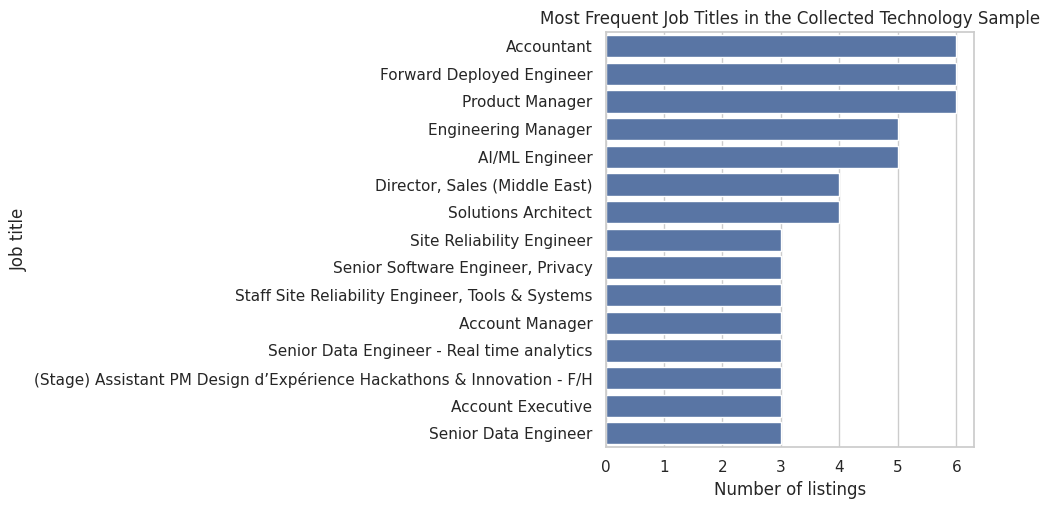

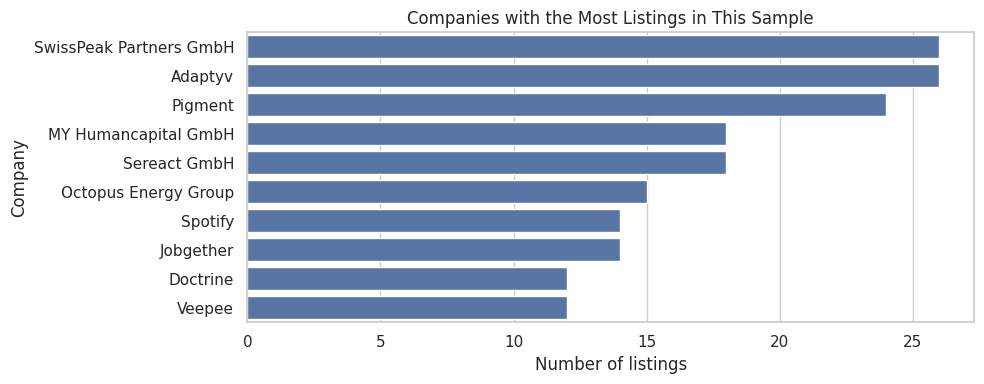

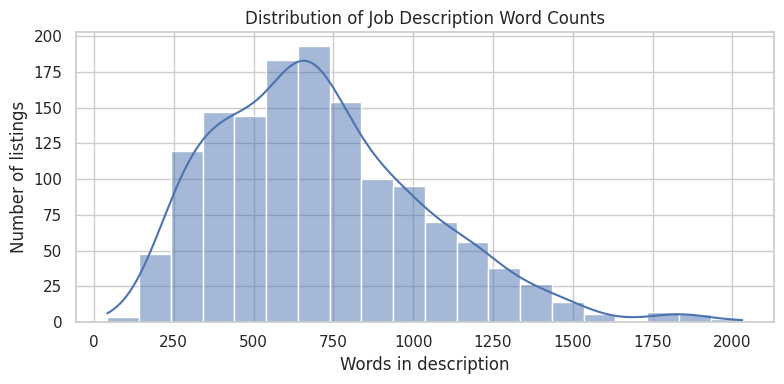

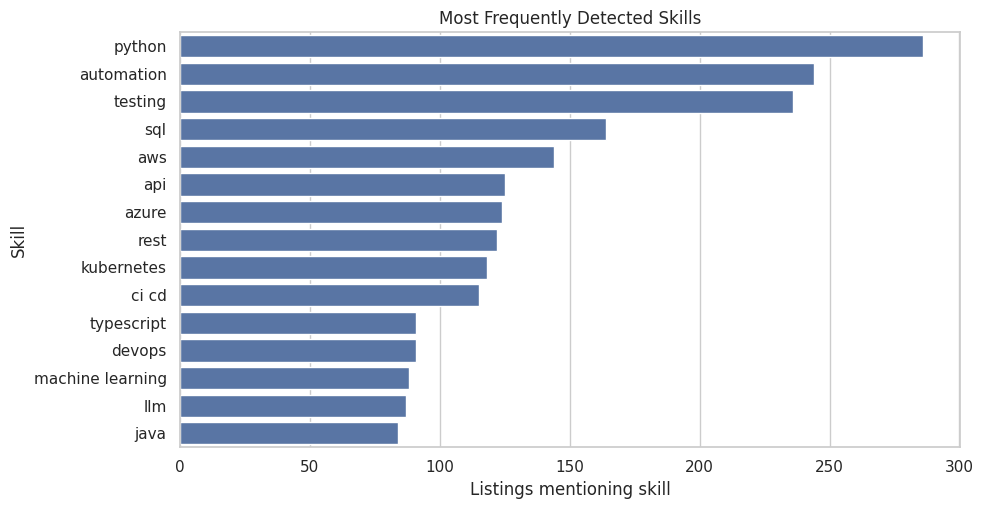

In [9]:
if not clean_df.empty:
    category_counts = (
        clean_df["job_title"]
        .fillna("Unknown")
        .value_counts()
        .head(15)
    )
    plt.figure(figsize=(10, max(4, 0.35 * len(category_counts))))
    sns.barplot(x=category_counts.values, y=category_counts.index)
    plt.title("Most Frequent Job Titles in the Collected Technology Sample")
    plt.xlabel("Number of listings")
    plt.ylabel("Job title")
    plt.tight_layout()
    plt.show()

    if clean_df["company_name"].notna().any():
        company_counts = clean_df["company_name"].fillna("Unknown").value_counts().head(10)
        plt.figure(figsize=(10, max(4, 0.35 * len(company_counts))))
        sns.barplot(x=company_counts.values, y=company_counts.index)
        plt.title("Companies with the Most Listings in This Sample")
        plt.xlabel("Number of listings")
        plt.ylabel("Company")
        plt.tight_layout()
        plt.show()

    plt.figure(figsize=(8, 4))
    sns.histplot(clean_df["description_word_count"], bins=20, kde=True)
    plt.title("Distribution of Job Description Word Counts")
    plt.xlabel("Words in description")
    plt.ylabel("Number of listings")
    plt.tight_layout()
    plt.show()

    skill_totals = skill_features.sum().sort_values(ascending=False) if "skill_features" in globals() else pd.Series(dtype=float)
    skill_totals = skill_totals[skill_totals > 0].head(15)
    if not skill_totals.empty:
        labels = [s.replace("skill_", "").replace("_", " ") for s in skill_totals.index]
        plt.figure(figsize=(10, max(4, 0.35 * len(skill_totals))))
        sns.barplot(x=skill_totals.values, y=labels)
        plt.title("Most Frequently Detected Skills")
        plt.xlabel("Listings mentioning skill")
        plt.ylabel("Skill")
        plt.tight_layout()
        plt.show()
    else:
        print("No dictionary skills were detected in this sample; the skill chart is skipped.")
else:
    print("No data available to plot.")

## 10. Feature scaling

Standardization and min-max scaling are demonstrated on numerical engineered features. Scaling is shown as a preprocessing example; it is not needed for every model and does not change the original columns.

In [10]:
scale_cols = [c for c in ["skill_count", "description_word_count"] if c in clean_df.columns]

if len(clean_df) >= 2 and scale_cols:
    scale_data = clean_df[scale_cols].fillna(clean_df[scale_cols].median())
    standard_scaler = StandardScaler()
    minmax_scaler = MinMaxScaler()

    standard_values = standard_scaler.fit_transform(scale_data)
    minmax_values = minmax_scaler.fit_transform(scale_data)

    scaled_df = pd.DataFrame(
        standard_values,
        columns=[f"{c}_zscore" for c in scale_cols],
        index=clean_df.index
    )
    for i, col in enumerate(scale_cols):
        clean_df[f"{col}_minmax"] = minmax_values[:, i]

    clean_df = pd.concat([clean_df, scaled_df], axis=1)
    print("Scaling completed. Preview:")
    display(clean_df[scale_cols + [f"{c}_zscore" for c in scale_cols] + [f"{c}_minmax" for c in scale_cols]].head())
else:
    print("At least two records and numerical features are needed to demonstrate scaling.")

Scaling completed. Preview:


,skill_count,description_word_count,skill_count_zscore,description_word_count_zscore,skill_count_minmax,description_word_count_minmax
0,4,322,0.523698,-1.176540,0.235294,0.140774
1,0,343,-0.741942,-1.112644,0.000000,0.151332
3,0,617,-0.741942,-0.278955,0.000000,0.289090
4,1,868,-0.425532,0.484753,0.058824,0.415284
5,0,501,-0.741942,-0.631904,0.000000,0.230769


## 11. Optional machine-learning experiment

A responsible prediction task requires a defensible target label and enough examples per class. The source's job titles are not a known hiring outcome, so this notebook does **not** claim to predict hiring success or salary. If there are enough records and at least two repeated title groups, the optional experiment predicts a coarse role family derived from title keywords using TF-IDF and logistic regression. This is a demonstration of text classification, not a model of job-market outcomes.

If the dataset is too small or the labels are too sparse, the experiment is skipped.

In [11]:
def role_family(title):
    t = (title or "").lower()
    if any(k in t for k in ["data scientist", "data analyst", "machine learning", "ai engineer", "artificial intelligence", "ml engineer"]):
        return "Data_AI"
    if any(k in t for k in ["security", "cybersecurity"]):
        return "Security"
    if any(k in t for k in ["devops", "site reliability", "sre", "cloud", "platform engineer", "systems administrator", "network engineer"]):
        return "Cloud_DevOps_IT"
    if any(k in t for k in ["developer", "software engineer", "programmer", "frontend", "front-end", "backend", "back-end", "full stack", "full-stack", "web engineer"]):
        return "Software_Development"
    if any(k in t for k in ["qa", "test engineer", "automation tester"]):
        return "Testing_QA"
    if any(k in t for k in ["technical support", "it support", "help desk"]):
        return "IT_Support"
    return "Other_Technology"

if len(clean_df) >= 30:
    ml_df = clean_df.copy()
    ml_df["role_family"] = ml_df["job_title"].apply(role_family)
    class_counts = ml_df["role_family"].value_counts()
    eligible_classes = class_counts[class_counts >= 3].index
    ml_df = ml_df[ml_df["role_family"].isin(eligible_classes)]

    if len(ml_df) >= 30 and ml_df["role_family"].nunique() >= 2:
        X = ml_df["full_text"].fillna("")
        y = ml_df["role_family"]
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=42, stratify=y
        )
        model = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=3000, ngram_range=(1, 2), stop_words="english")),
            ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
        ])
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        print("Target: title-derived role family")
        print("Test accuracy:", round(accuracy_score(y_test, predictions), 3))
        print("\nClassification report:")
        print(classification_report(y_test, predictions, zero_division=0))
        print("Interpretation: this predicts heuristic role-family labels, not job availability or hiring success.")
    else:
        print("ML experiment skipped: insufficient examples per role family after filtering.")
else:
    print(f"ML experiment skipped: only {len(clean_df)} technology listings; at least 30 are required for this demonstration.")

Target: title-derived role family
Test accuracy: 0.712

Classification report:
                      precision    recall  f1-score   support

     Cloud_DevOps_IT       0.43      0.77      0.56        13
             Data_AI       0.35      0.56      0.43        16
          IT_Support       0.04      0.50      0.08         2
    Other_Technology       0.94      0.73      0.82       282
            Security       0.67      0.80      0.73         5
Software_Development       0.45      0.62      0.52        34
          Testing_QA       0.09      0.50      0.15         2

            accuracy                           0.71       354
           macro avg       0.42      0.64      0.47       354
        weighted avg       0.84      0.71      0.76       354

Interpretation: this predicts heuristic role-family labels, not job availability or hiring success.


## 12. Export cleaned data and collection logs

The notebook saves the collected raw records, filtered/engineered dataset, and collection log as CSV files. The description HTML is retained in the raw dataset; the cleaned text description is stored separately. These files can be downloaded from Colab's Files panel.

In [12]:
raw_export = raw_df.copy()
engineered_export = clean_df.copy()

raw_export.to_csv("raw_job_listings.csv", index=False)
engineered_export.to_csv("technology_jobs_feature_engineered.csv", index=False)
page_log_df.to_csv("collection_log.csv", index=False)

print("Export complete:")
print("- raw_job_listings.csv")
print("- technology_jobs_feature_engineered.csv")
print("- collection_log.csv")
print("\nFinal raw records:", len(raw_export))
print("Final technology records:", len(engineered_export))
print("Final engineered columns:", len(engineered_export.columns))

Export complete:
- raw_job_listings.csv
- technology_jobs_feature_engineered.csv
- collection_log.csv

Final raw records: 1500
Final technology records: 1415
Final engineered columns: 82


## 13. Final verification and conclusion notes

Use the outputs produced above to write the final report. Record the actual collection date, number of raw listings, number of technology-related listings, missing-value counts, detected skills, and charts. Do not copy placeholder numbers into the report.

### Limitations
- The source is a public job-board API and its available records and schema may change.
- The collected sample is not a census of all technology vacancies.
- Keyword filtering and skill extraction are heuristic and can misclassify jobs or miss synonyms.
- Salary fields may be absent or incomparable; no salary conclusion should be made without sufficient valid data.
- A title-derived role-family classifier only evaluates its own heuristic labels and must not be interpreted as predicting hiring outcomes.

### Completion checklist
- [ ] API collection completed and page log reviewed
- [ ] Technology filter inspected for false positives/negatives
- [ ] Missing values and duplicates reviewed
- [ ] Feature engineering results checked
- [ ] All generated charts reviewed
- [ ] CSV exports downloaded
- [ ] Final assignment written using actual outputs and graphs